In [1]:
# 更新履歴
# 2026-10-07 作成

# 基本モジュール
import sys, os
from IPython.display import display, HTML, clear_output, update_display, Image
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import matplotlib
import pyFAI
import pandas as pd
import h5py
import plotly.express as px
import plotly.graph_objects as go
from tqdm import tqdm
import PIL.Image as im
import json
from pprint import pprint
from sklearn.model_selection import train_test_split
import random as rd

# fpdファイル取扱い用
import threading
import concurrent.futures as confu

# 自作モジュール
sys.path.append(r"G:\python\modules-main")
from Mytools.Tools import h5_tree, dict_tree, his2array, simple_progress_bar
import Mytools.Settings
sys.path.append(os.getcwd())

## RSF則

In [2]:
def generate_rs_data(
        V_func: function,
        setting: dict,
        t_eval: np.ndarray
        ) -> tuple[np.ndarray, np.ndarray]:

    """
    与えられた速度軌道 V(t) に対して
    従来型RS摩擦係数f_RS(t)を計算する
    """

    D_RS = setting["D_RS"]
    def theta_dot(t, theta):
        V = V_func(t)
        return 1. - (V*theta)/D_RS

    # 初期状態
    V0 = V_func(t_eval[0])
    theta0 = [D_RS/V0]

    # 常微分方程式の数値解法（RK45）
    sol = sp.integrate.solve_ivp(
        theta_dot,
        (t_eval[0], t_eval[-1]),
        theta0,
        t_eval = t_eval,
        method = 'RK45'
    )
    theta_sol = sol.y[0]

    # 摩擦係数 f_RS の計算
    f_star = setting["f_star"]
    V_star = setting["V_star"]
    a = setting["a"]
    b = setting["b"]
    V_sol = np.array([V_func(t) for t in t_eval])
    if np.any(V_sol <= 0):
        raise RuntimeError("V_sol is negative")
    if np.any(theta_sol <= 0):
        raise RuntimeError("theta_sol is negative")
    
    f_RS = f_star + a*np.log(V_sol / V_star) + b*np.log(V_star*theta_sol/D_RS)

    return V_sol, f_RS

## ランダムな速度構造を与える関数

In [3]:

def create_velocity_jump_func(T=1.98, log_v_min=-7.0, log_v_max=-3.0, num_jumps=3):
    rng = np.random.default_rng()

    """① 速度跳躍 (Velocity Jump) 軌道を生成"""
    # 0~Tの間でランダムなジャンプ時刻を設定
    jump_times = sorted(rng.uniform(low = 0.1, high = T-0.1, size=num_jumps))
    jump_times = [0.0] + jump_times + [T + 0.1]
    
    # 各区間の log10(V/V*) をランダム設定
    log_v_values = rng.uniform(low = log_v_min, high =log_v_max, size=num_jumps + 1)
    
    def V_func(t):

        # 区間番号を取得
        idx = np.searchsorted(
            jump_times,
            t,
            side='right'
        ) - 1

        # 範囲外を対策
        idx = np.clip(idx, 0, len(log_v_values) - 1)

        return np.power(10, log_v_values[idx])
        
    return V_func

def create_continuous_variation_func(T=1.98, log_v_min=-7., log_v_max=-3., num_control_points=5):
    """② 連続変化 (Continuous Variation) 軌道を生成"""

    rng = np.random.default_rng()

    # 時間軸上のいくつかの点でランダムな log10(V/V*) を設定
    t_points = sorted(rng.uniform(low = 0.1, high = T-0.1, size=num_control_points))
    log_v_values = rng.uniform(low = log_v_min, high = log_v_max, size=num_control_points)
    
    # スプライン補間（または線形補間）で連続化
    interp_func = sp.interpolate.interp1d(t_points, log_v_values, kind='linear', fill_value="extrapolate")
    
    def V_func(t):
        log_v = np.clip(interp_func(t), log_v_min, log_v_max)
        return np.power(10, log_v)
        
    return V_func

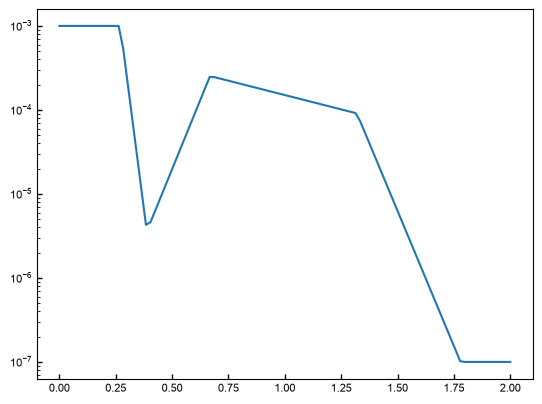

In [4]:
V_func = create_continuous_variation_func()

t_eval = np.linspace(0,2,100)
plt.plot(t_eval, V_func(t_eval))
plt.yscale("log")
plt.show()

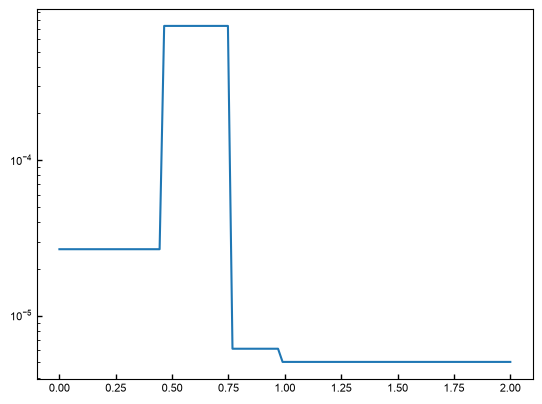

In [5]:
V_func = create_velocity_jump_func()
t_eval = np.linspace(0,2,100)
plt.plot(t_eval, V_func(t_eval))
plt.yscale("log")
plt.show()

In [6]:
def create_velocity_func() -> function:

    mode_f = rd.random()
    if mode_f < 0.5:
        func = create_velocity_jump_func
    else:
        func = create_continuous_variation_func

    num = rd.randrange(2,6)

    return func(1.98,-7,-3,num)

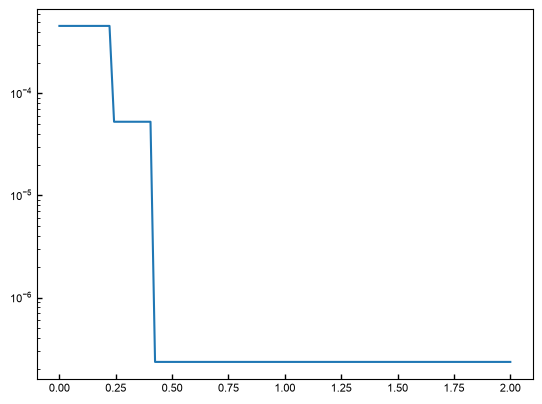

In [7]:
V_func = create_velocity_func()
t_eval = np.linspace(0,2,100)
plt.plot(t_eval, V_func(t_eval))
plt.yscale("log")
plt.show()

## データの生成

In [8]:
setting = {
    'a': 0.011,
    'b': 0.016,
    'f_star': 0.5109,
    'V_star': 1e-4,
    'D_RS': 1e-6
}

In [9]:
output_hdf = r"F:\DATA\SPReAD1000_2026-Oct\Teacher\2.hdf"

t_eval = np.linspace(0,2,100)
data_len = 800

with h5py.File(output_hdf, mode = "w") as f:
    for k in setting.keys():
        f.attrs[k] = setting[k]
    for i in range(data_len):
        g = f.create_group(
            name = str(i)
        )
        g.create_dataset(
            name = "velocity",
            shape = (100,),
            dtype = np.float64
        )
        g.create_dataset(
            name = "friction",
            shape = (100,),
            dtype = np.float64
        )

for i in tqdm(range(data_len)):
    while True:
        v_func = create_velocity_func()
        try:
            V_sol, f_RS = generate_rs_data(
                V_func = v_func,
                setting = setting,
                t_eval = t_eval
            )
        except:
            continue
        else:
            break

    with h5py.File(output_hdf, mode = "r+") as f:
        f[str(i)]["velocity"][()] = V_sol
        f[str(i)]["friction"][()] = f_RS
        
with h5py.File(output_hdf, mode = "r") as f:
    h5_tree(f)

100%|██████████| 800/800 [00:25<00:00, 31.69it/s]


<HDF5 file "2.hdf" (mode r)>
├── 0
│   ├── friction ((100,), float64)
│   └── velocity ((100,), float64)
├── 1
│   ├── friction ((100,), float64)
│   └── velocity ((100,), float64)
├── 10
│   ├── friction ((100,), float64)
│   └── velocity ((100,), float64)
├── 100
│   ├── friction ((100,), float64)
│   └── velocity ((100,), float64)
├── 101
│   ├── friction ((100,), float64)
│   └── velocity ((100,), float64)
├── 102
│   ├── friction ((100,), float64)
│   └── velocity ((100,), float64)
├── 103
│   ├── friction ((100,), float64)
│   └── velocity ((100,), float64)
├── 104
│   ├── friction ((100,), float64)
│   └── velocity ((100,), float64)
├── 105
│   ├── friction ((100,), float64)
│   └── velocity ((100,), float64)
├── 106
│   ├── friction ((100,), float64)
│   └── velocity ((100,), float64)
├── 107
│   ├── friction ((100,), float64)
│   └── velocity ((100,), float64)
├── 108
│   ├── friction ((100,), float64)
│   └── velocity ((100,), float64)
├── 109
│   ├── friction ((100,), float6